# Cancer Classification Using Neural Networks

## Project Description
This project uses an Artificial Neural Network (ANN) to classify breast cancer tumours as benign or malignant using the Breast Cancer Wisconsin dataset.

The model analyzes different features of cell nuclei and learns patterns from the dataset to predict the type of tumour.

## Objective
To develop a neural network model that can classify breast cancer tumours and evaluate its performance using accuracy, precision, recall, F1-score and a confusion matrix.

## Tools and Technologies
- Python
- Google Colab
- TensorFlow and Keras
- NumPy and Pandas
- Matplotlib
- Scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

Libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Total samples:", X.shape[0])
print("Total features:", X.shape[1])
print("Target classes:", data.target_names)

Dataset loaded successfully!
Total samples: 569
Total features: 30
Target classes: ['malignant' 'benign']


## Data Preprocessing

Data preprocessing is performed to prepare the dataset for neural network training.

The dataset is divided into training and testing sets. Feature scaling is applied using StandardScaler to bring the numerical features to a similar scale.

- 80% data is used for training.
- 20% data is used for testing.
- Stratified splitting maintains the proportion of both classes.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data preprocessing completed!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Data preprocessing completed!
Training samples: 455
Testing samples: 114


In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.8407 - loss: 0.4717 - val_accuracy: 0.9231 - val_loss: 0.3894
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9423 - loss: 0.3318 - val_accuracy: 0.9780 - val_loss: 0.2868
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9396 - loss: 0.2581 - val_accuracy: 0.9670 - val_loss: 0.2197
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9560 - loss: 0.1998 - val_accuracy: 0.9670 - val_loss: 0.1745
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9698 - loss: 0.1531 - val_accuracy: 0.9780 - val_loss: 0.1431
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9588 - loss: 0.1380 - val_accuracy: 0.9780 - val_loss: 0.1214
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9643 - loss: 0.1335 - val_accuracy: 0.9780 - val_loss: 0.1063
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9698 - loss: 0.1099 - val_accuracy: 0.9780 - val_l

In [6]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9649 - loss: 0.1246
Test Accuracy: 96.49122953414917 %
Test Loss: 0.12460432201623917


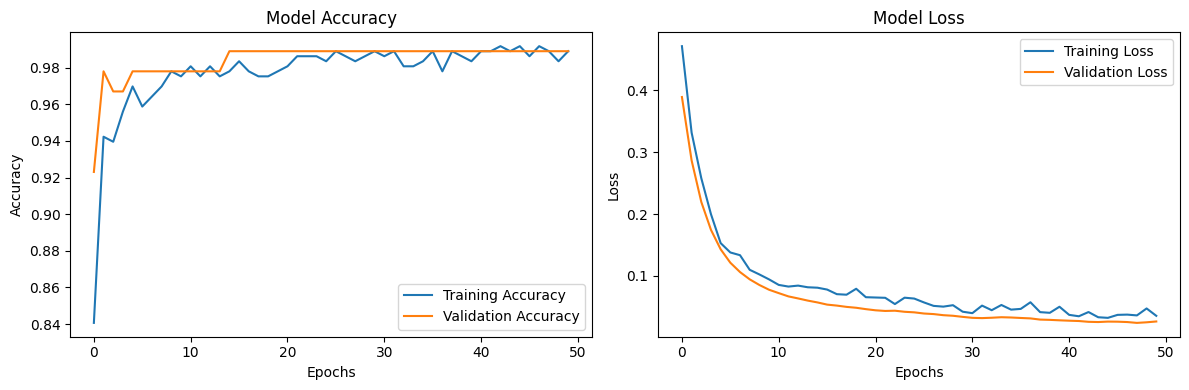

In [7]:
plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



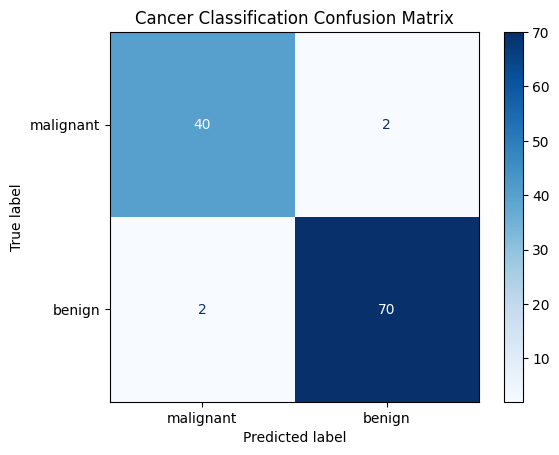

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Generate predictions
y_probability = model.predict(X_test, verbose=0)
y_pred = (y_probability >= 0.5).astype(int).ravel()

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Cancer Classification Confusion Matrix")
plt.show()

In [9]:
index = 0

sample = X_test[index].reshape(1, -1)

prediction = model.predict(sample, verbose=0)[0][0]

predicted_class = 1 if prediction >= 0.5 else 0

print("Predicted Tumour:", data.target_names[predicted_class])
print("Actual Tumour:", data.target_names[y_test[index]])
print("Prediction Probability:", prediction)

Predicted Tumour: malignant
Actual Tumour: malignant
Prediction Probability: 5.295674e-13


In [10]:
model.save("cancer_classification_model.keras")

print("Cancer classification model saved successfully!")

Cancer classification model saved successfully!
